# Lezione 2 — I dati e le parole: come trasformare testi in numeri?
**Machine Learning for the Humanities · 5 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/02_dati_e_parole_alberi.ipynb)

**Laboratorio:** liste, cicli, frequenze, tabelle e un CSV. **Metodo:** l'albero di decisione.

Un computer non legge: **conta**. Oggi impariamo a trasformare un testo in numeri (frequenze, misure di stile) e scopriamo
che cosa può farne un **albero di decisione**. Il nostro testo guida è *Le avventure di Pinocchio* (1883): un libro in cui
la *contentezza* arriva spesso un attimo prima del guaio.

### Obiettivi di apprendimento
1. leggere un file di testo e dividerlo in parole (**tokenizzazione**);
2. contare le frequenze con un ciclo, con un dizionario e con `Counter`;
3. costruire una tabella (`DataFrame`) e salvarla come **CSV**;
4. descrivere un testo con un vettore di **caratteristiche** numeriche;
5. addestrare e leggere un **albero di decisione**.

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

def parole(testo):
    """Spezza un testo in parole minuscole."""
    return re.findall(r"\w+", testo.lower())

def leggi_testo(nome):
    """Legge un testo dalla cartella data/testi, saltando le righe di intestazione che iniziano con #."""
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

STOPWORDS = set()
for riga in (DATI / "stopwords_it.txt").read_text(encoding="utf-8").splitlines():
    if not riga.startswith("#"):
        STOPWORDS.update(riga.split())

famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FAMIGLIA_DI = dict(zip(famiglie["forma"], famiglie["famiglia"]))   # forma → famiglia, es. "lieta" → "letizia"
FAMIGLIE = list(dict.fromkeys(famiglie["famiglia"]))

RISULTATI = Path("risultati")
RISULTATI.mkdir(exist_ok=True)      # qui salveremo i nostri CSV

## 1. Leggere un testo

In [3]:
pinocchio = leggi_testo("collodi_pinocchio.txt")
print(len(pinocchio), "caratteri")
print(pinocchio[:600])

247879 caratteri

I.
Come andò che Maestro Ciliegia, falegname trovò un pezzo di legno che piangeva e rideva come un bambino.

— C'era una volta....

— Un re! — diranno subito i miei piccoli lettori.

— No, ragazzi, avete sbagliato. C'era una volta un pezzo di legno.

Non era un legno di lusso, ma un semplice pezzo da catasta, di quelli
che d'inverno si mettono nelle stufe e nei caminetti per accendere il
fuoco e per riscaldare le stanze.

Non so come andasse, ma il fatto gli è che un bel giorno questo pezzo
di legno capitò nella bottega di un vecchio falegname, il quale aveva
nome mastr'Antonio, se non che tu


## 2. Tokenizzare: dal testo alla lista di parole
**Tokenizzare** vuol dire spezzare il testo in unità (*token*). Noi usiamo una regola semplice: una parola è una sequenza di lettere.
Ogni scelta ha conseguenze: *l'acqua* diventa `l` + `acqua`; *Pinocchio* e *pinocchio* diventano uguali.

In [4]:
tokens = parole(pinocchio)
print("Token (parole totali):", len(tokens))
print("Tipi (parole diverse):", len(set(tokens)))
print(tokens[:30])

Token (parole totali): 41562
Tipi (parole diverse): 6080
['i', 'come', 'andò', 'che', 'maestro', 'ciliegia', 'falegname', 'trovò', 'un', 'pezzo', 'di', 'legno', 'che', 'piangeva', 'e', 'rideva', 'come', 'un', 'bambino', 'c', 'era', 'una', 'volta', 'un', 're', 'diranno', 'subito', 'i', 'miei', 'piccoli']


## 3. Contare le frequenze
### 3a. Con un ciclo e un dizionario
Un **dizionario** associa una chiave a un valore: qui ogni parola al numero di volte che compare.

In [5]:
frequenze = {}
for p in tokens:
    if p in frequenze:
        frequenze[p] = frequenze[p] + 1
    else:
        frequenze[p] = 1

print("burattino:", frequenze["burattino"])
print("contentezza:", frequenze["contentezza"])

burattino: 203
contentezza: 10


### 3b. Con `Counter`, la scorciatoia di Python
Fa la stessa cosa in una riga, e sa anche ordinare.

In [6]:
conta = Counter(tokens)
conta.most_common(15)

[('e', 1798),
 ('di', 1361),
 ('che', 1026),
 ('a', 960),
 ('il', 946),
 ('un', 792),
 ('la', 727),
 ('non', 508),
 ('per', 504),
 ('in', 461),
 ('pinocchio', 448),
 ('si', 398),
 ('gli', 373),
 ('una', 366),
 ('è', 304)]

Le parole più frequenti sono **parole funzionali** (*e, di, il, che…*): dicono molto sullo *stile*, poco sul *contenuto*.
Per vedere il contenuto togliamo una lista di **stopwords** (la trovate in `data/stopwords_it.txt`: potete modificarla).

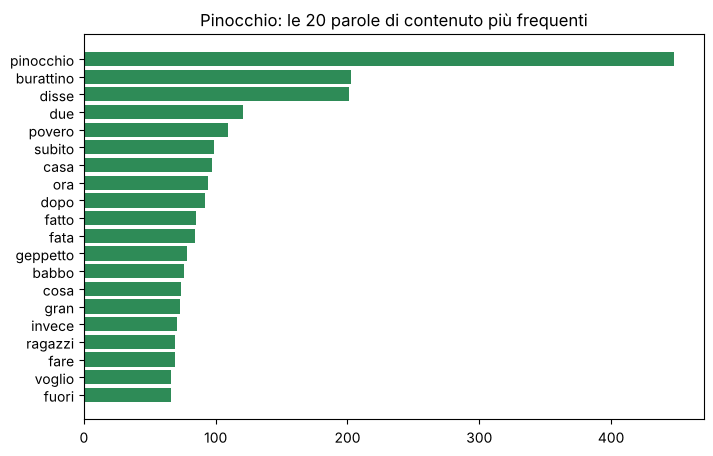

In [7]:
contenuto = Counter(p for p in tokens if p not in STOPWORDS and len(p) > 2)
top = contenuto.most_common(20)

parole_top = [p for p, n in top]
conteggi_top = [n for p, n in top]
plt.figure(figsize=(8, 5))
plt.barh(parole_top[::-1], conteggi_top[::-1], color="seagreen")
plt.title("Pinocchio: le 20 parole di contenuto più frequenti")
plt.show()

## 4. Dalle frequenze a una tabella
Una tabella (`DataFrame`) è il formato naturale dei dati: righe = osservazioni, colonne = variabili.
Confrontiamo alcune parole in *Pinocchio* e nei *Promessi sposi*. Usiamo la **frequenza relativa** (ogni 1000 parole),
perché i due libri hanno lunghezze molto diverse.

In [8]:
promessi = leggi_testo("manzoni_promessi_sposi.txt")
tok_ps = parole(promessi)
conta_ps = Counter(tok_ps)

righe = []
for p in ["felice", "contento", "allegria", "lieto", "gioia", "povero", "fame", "dio", "provvidenza"]:
    righe.append({
        "parola": p,
        "pinocchio_x1000": conta[p] / len(tokens) * 1000,
        "promessi_sposi_x1000": conta_ps[p] / len(tok_ps) * 1000,
    })
confronto = pd.DataFrame(righe).round(3)
confronto

,parola,pinocchio_x1000,promessi_sposi_x1000
0,felice,0.048,0.067
1,contento,0.337,0.166
2,allegria,0.024,0.054
3,lieto,0.000,0.022
4,gioia,0.072,0.121
5,povero,2.623,0.517
6,fame,0.914,0.099
7,dio,0.144,0.917
8,provvidenza,0.024,0.099


## 5. La felicità capitolo per capitolo
Ora un ciclo dentro un ciclo: per ogni capitolo, per ogni parola, controlliamo se appartiene a una delle sei **famiglie** della felicità
(*felicità, gioia, allegria, contentezza, letizia, beatitudine*).

In [9]:
capitoli = pd.read_csv(DATI / "pinocchio_capitoli.csv")

righe = []
for _, cap in capitoli.iterrows():
    conteggi = {f: 0 for f in FAMIGLIE}
    for p in parole(cap["testo"]):
        if p in FAMIGLIA_DI:
            conteggi[FAMIGLIA_DI[p]] += 1
    conteggi["capitolo"] = cap["capitolo"]
    conteggi["n_parole"] = len(parole(cap["testo"]))
    righe.append(conteggi)

felicita_pin = pd.DataFrame(righe).set_index("capitolo")
felicita_pin["totale_1000"] = felicita_pin[FAMIGLIE].sum(axis=1) / felicita_pin["n_parole"] * 1000
felicita_pin.head(8)

,felicità,gioia,allegria,contentezza,letizia,beatitudine,n_parole,totale_1000
capitolo,,,,,,,,
1,0,0,0,1,0,0,648,1.543210
2,0,0,0,1,0,0,609,1.642036
3,0,0,1,0,0,0,1022,0.978474
4,0,0,0,2,0,0,585,3.418803
5,0,1,1,0,0,0,633,3.159558
6,0,0,0,0,0,0,399,0.000000
7,0,0,0,1,0,0,884,1.131222
8,0,0,0,2,0,0,614,3.257329


In [10]:
felicita_pin[FAMIGLIE].sum().sort_values(ascending=False)

contentezza    28
allegria       21
felicità        5
gioia           3
letizia         0
beatitudine     0
dtype: int64

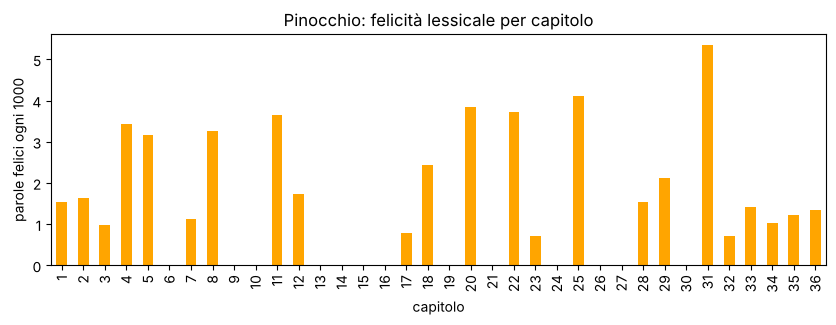

Il capitolo più 'felice' è il 31 : Dopo cinque mesi di cuccagna, Pinocchio con sua gran meraviglia sente spuntarsi un bel pajo d'orecchie asinine, e diventa un ciuchino, con la coda e tutto.


In [11]:
felicita_pin["totale_1000"].plot(kind="bar", figsize=(10, 3), color="orange")
plt.ylabel("parole felici ogni 1000"); plt.title("Pinocchio: felicità lessicale per capitolo"); plt.show()

piu_felice = felicita_pin["totale_1000"].idxmax()
print("Il capitolo più 'felice' è il", piu_felice, ":", capitoli.loc[capitoli["capitolo"] == piu_felice, "titolo"].iloc[0])

Il capitolo più "felice" è quello in cui Pinocchio, dopo cinque mesi nel **Paese dei balocchi**, si ritrova con le orecchie d'asino.
La felicità lessicale è massima proprio dove Collodi la mostra come una trappola: i numeri ci dicono *dove guardare*,
non *che cosa significa*.

In *Pinocchio* domina la **contentezza**, e non la *beatitudine*: è la felicità quotidiana e un po' ingenua del burattino
(*"si rallegrò tutto; e dandosi una fregatina di mani per la contentezza…"*). Le frequenze dicono qualcosa sul **registro** di un libro.

## 6. Salvare un CSV
Un **CSV** (*comma-separated values*) è un file di testo con una tabella: si apre con Excel, LibreOffice, Google Sheets o con Python.

In [12]:
felicita_pin.to_csv(RISULTATI / "pinocchio_felicita.csv")
print((RISULTATI / "pinocchio_felicita.csv").read_text()[:300])

capitolo,felicità,gioia,allegria,contentezza,letizia,beatitudine,n_parole,totale_1000
1,0,0,0,1,0,0,648,1.5432098765432098
2,0,0,0,1,0,0,609,1.6420361247947455
3,0,0,1,0,0,0,1022,0.9784735812133072
4,0,0,0,2,0,0,585,3.4188034188034186
5,0,1,1,0,0,0,633,3.1595576619273302
6,0,0,0,0,0,0,399,0.0
7,0,0,


## 7. Dai testi ai numeri: un vettore di caratteristiche
Per il *machine learning* ogni testo deve diventare una **riga di numeri** (un *vettore*). Qui scegliamo noi le misure
(lunghezza delle parole e delle frasi, punteggiatura, parole funzionali, parole felici). È l'idea della **stilometria**.

Usiamo `passaggi_autori.csv`: brani di circa 200 parole da cinque autori (Collodi, Manzoni, Deledda, Pirandello, Di Giacomo).

In [13]:
import numpy as np

def caratteristiche(testo):
    """Trasforma un testo in una riga di numeri (caratteristiche stilistiche)."""
    p = parole(testo)
    frasi = [f for f in re.split(r"[.!?]+", testo) if f.strip()]
    n = len(p)
    return {
        "lung_media_parola": np.mean([len(x) for x in p]),
        "parole_per_frase": n / len(frasi),
        "esclamativi_100": testo.count("!") / n * 100,
        "trattini_100": testo.count("—") / n * 100,        # il trattino lungo introduce i dialoghi
        "punto_e_virgola_100": testo.count(";") / n * 100,
        "funzionali_100": sum(x in STOPWORDS for x in p) / n * 100,
        "felici_1000": sum(x in FAMIGLIA_DI for x in p) / n * 1000,
    }

In [14]:
passaggi = pd.read_csv(DATI / "passaggi_autori.csv")
print(passaggi["autore"].value_counts())

X_tutti = pd.DataFrame([caratteristiche(t) for t in passaggi["testo"]])
X_tutti["autore"] = passaggi["autore"]
X_tutti.groupby("autore").mean().round(2)

autore
Collodi       120
Manzoni       120
Deledda       120
Pirandello    120
Di Giacomo    120
Name: count, dtype: int64


,lung_media_parola,parole_per_frase,esclamativi_100,trattini_100,punto_e_virgola_100,funzionali_100,felici_1000
autore,,,,,,,
Collodi,4.56,16.66,1.70,4.84,0.45,47.66,1.50
Deledda,4.71,15.41,1.10,3.42,0.94,44.76,1.09
Di Giacomo,4.77,14.63,1.14,3.19,0.45,44.86,0.52
Manzoni,4.59,26.08,0.68,0.00,1.80,47.43,1.31
Pirandello,4.60,19.79,1.18,2.10,0.95,48.14,0.80


## 8. L'albero di decisione
Un **albero di decisione** impara una serie di domande sì/no ("le frasi sono più lunghe di 20 parole?") che separano le classi.
È il metodo più facile da *leggere*: possiamo vedere esattamente le regole che ha trovato.

Cominciamo con due autori: **Collodi o Manzoni?** Dividiamo i dati in due parti: una per **addestrare** (*train*),
una per **verificare** (*test*) su brani che l'albero non ha mai visto.

In [15]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

due = X_tutti[X_tutti["autore"].isin(["Collodi", "Manzoni"])]
X = due.drop(columns="autore")
y = due["autore"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

albero = DecisionTreeClassifier(max_depth=2, random_state=0)
albero.fit(X_train, y_train)
print("Accuratezza sui brani di test:", round(albero.score(X_test, y_test) * 100, 1), "%")

Accuratezza sui brani di test: 98.6 %


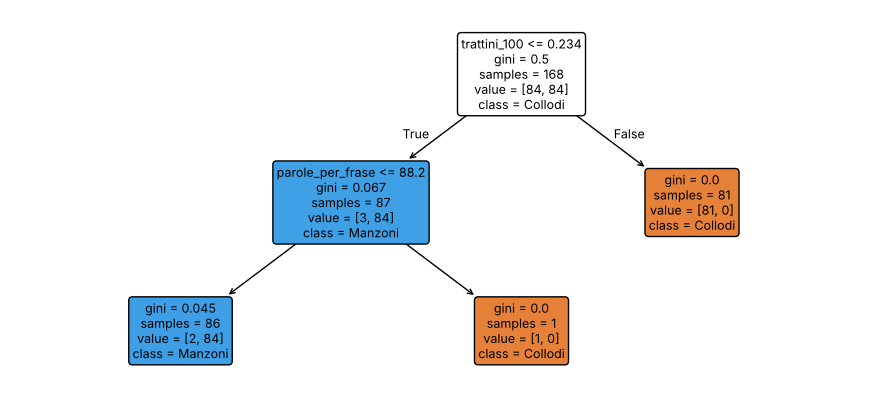

In [16]:
plt.figure(figsize=(11, 5))
plot_tree(albero, feature_names=X.columns, class_names=albero.classes_, filled=True, rounded=True, fontsize=9)
plt.show()

**Come leggere l'albero.** Ogni riquadro è una domanda; a sinistra si va se la risposta è *vera*. `samples` è il numero di brani
che arrivano lì, `value` quanti per classe, `class` la risposta dell'albero. Il **gini** misura quanto il gruppo è ancora "mescolato"
(0 = tutti dello stesso autore).

L'albero ha scoperto da solo un fatto filologico: in questa edizione Manzoni usa le virgolette e non il trattino per i dialoghi,
e scrive frasi lunghe e ricche di punti e virgola. È una regola utile, ma anche **fragile**: dipende dall'edizione, non dall'autore!

In [17]:
prova = "— Che cosa vuoi? — gridò il burattino. — Non ho fame! Voglio andare a casa!"
print(albero.predict(pd.DataFrame([caratteristiche(prova)]))[0])

Collodi


## Riepilogo
- **Token** e **tipi**; frequenze **assolute** e **relative**.
- Le **stopwords** nascondono lo stile ma rivelano il contenuto (e viceversa).
- Ogni testo può diventare un **vettore di caratteristiche**: le scegliamo noi, e la scelta è già un'interpretazione.
- Un **albero di decisione** impara domande sì/no leggibili; `max_depth` controlla quanto può diventare complicato.

## Esercizi
Soluzioni in `solutions/02_dati_e_parole_alberi_soluzioni.ipynb`.

**Esercizio 1 — Le parole di una poesia.** Prendete *A Silvia* da `leopardi_canti.csv` e mostrate le 10 parole di contenuto più frequenti
(senza stopwords). Che cosa ci dicono della poesia?

**Esercizio 2 — Un CSV della felicità leopardiana.** Per ognuna delle 40 poesie dei *Canti* contate le parole di ciascuna famiglia
della felicità e salvate la tabella in `risultati/leopardi_felicita.csv` (colonne: titolo, n_parole, una colonna per famiglia).
Quale famiglia domina in Leopardi? E in Pinocchio?

**Esercizio 3 — Cinque autori.** Addestrate un albero di decisione su **tutti e cinque** gli autori (`X_tutti`), con `max_depth=3`.
Qual è l'accuratezza sul test? Quali caratteristiche usa di più (`albero.feature_importances_`)? Che cosa succede con `max_depth=10`?

In [18]:
# Esercizio 1

In [19]:
# Esercizio 2

In [20]:
# Esercizio 3